# Window re-check: which history signals survive the retention windows?

Post-interim follow-up to the history timeline (E01, FINDINGS section 7): clicks are kept for 7 days, carts and follows for 90 days, orders for 365 days. Several interim results pooled these windows. This notebook re-checks the ones our feature design and main story build on:

| Experiment | Question |
|---|---|
| **E03** | Which windows and action types carry ranking signal? Separate **type** (compare types within 0-7 days, where all are kept) from **age** (compare the same type across windows). |
| **E04** | Does the interim context lead (history helps more right after the last action, FINDINGS section 6) survive when the visible action types are held fixed? |
| **E05** | Leakage and re-finds: do history actions look like the current search's own interactions? Do shop and brand matches still help without the candidate's own product? |

**Data.** 20,000 searches drawn (seed 4222) from the 40,000-record **dev subsample of the training split** (`split_v1`). Validation and test are not touched, so feature decisions made here do not leak into model evaluation.

**Method.** Same idea as the interim signal checks, now with the shared evaluation (`scripts/evaluation.py`): rank each complete candidate list by one signal (number of matching history actions), compute NDCG@10 exactly under random tie-breaking and subtract the random-order NDCG@10 of the same search. *Gain* = signal NDCG@10 minus random. Matches use the interim rules: category on the full ancestor path, missing metadata never matches.

These are untrained single-signal rankings: associations that guide feature design, not model results.

**Run time:** one pass over the behaviour file, one over the catalogue (4.8 GB), then the signal computation; roughly 10-15 minutes locally.

In [1]:
from collections import Counter
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REPO_ROOT = next((p.resolve() for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "scripts/evaluation.py").is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open/clone the repository checkout first.")
if IN_COLAB:
    drive.mount("/content/drive")
    DATA_DIR = Path("/content/drive/MyDrive/BT4222 Group Project/data")
else:
    DATA_DIR = REPO_ROOT / "data"
BEHAVIOUR, CATALOGUE = DATA_DIR / "user_behavior_data.txt", DATA_DIR / "product_meta_data.txt"
OUT = REPO_ROOT / "outputs/eda/window_recheck"
OUT.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(REPO_ROOT))
from scripts.jd_data import iter_records, load_metadata, SECONDS_PER_DAY
from scripts.evaluation import expected_metrics, bootstrap_interval
from scripts.history_match_diagnostics import metadata_keys, validate_match_helpers
from scripts.query_diagnostics import token_set

validate_match_helpers()
SEED, SAMPLE_SIZE = 4222, 20_000
pd.options.display.float_format = "{:,.4f}".format

## 1. Sample and load

The split file is written by `02_split_and_evaluation.ipynb`; run that notebook first.

In [2]:
assignment = pd.read_csv(REPO_ROOT / "data/processed/split_v1.csv", index_col="session_id")
dev_ids = assignment.index[assignment.dev_subsample].to_numpy()
assert (assignment.loc[dev_ids, "split"] == "train").all()
sample_ids = np.sort(np.random.default_rng(SEED).choice(dev_ids, SAMPLE_SIZE, replace=False))
selected = set(sample_ids.tolist())

records, needed = [], set()
for session_id, fields in iter_records(BEHAVIOUR):
    if session_id not in selected:
        continue
    candidates = fields[1].split("_")
    labels = np.array([int(float(v)) for v in fields[2].split("_")], dtype=np.int8)
    past = fields[4].split("_")
    types = np.array(fields[5].split("_"))
    queries = fields[3].split("_")
    gaps = np.array(fields[6].split("_"), dtype=np.int64)
    elapsed_s = np.cumsum(gaps[::-1])[::-1][1:]  # seconds from each past action to the search
    assert len(past) == len(types) == len(queries) == len(elapsed_s)
    records.append(dict(session_id=session_id, query=fields[0], candidates=candidates, labels=labels, past=past,
                        types=types, queries=queries, elapsed_s=elapsed_s, last_gap_s=int(gaps[-1])))
    needed.update(candidates)
    needed.update(past)
print(f"records: {len(records):,}; products needing metadata: {len(needed):,}")

start = time.time()
metadata = load_metadata(CATALOGUE, needed)
print(f"catalogue rows found: {len(metadata):,} ({len(metadata) / len(needed):.1%}) in {time.time() - start:.0f} s")

records: 20,000; products needing metadata: 2,338,516


catalogue rows found: 2,229,694 (95.3%) in 22 s


## 2. History blocks and match levels

Each signal counts the past actions in one **block** of history that match the candidate at one **level**.

| Block | Actions | Used for |
|---|---|---|
| pooled | all history | interim reference |
| no clicks | carts, orders, follows of any age | E04: removes the 7-day click window |
| older than 7 d | carts, orders, follows at least 7 days before the search | E04: same availability for every shopper |
| 0-7 d CLICK / CART / ORD | each type within the last 7 days | E03: type at fixed age |
| 7-90 d CART / ORD | each type 7-90 days before | E03: age at fixed type |
| 90-365 d ORD | orders 90+ days before | E03: age at fixed type |

Levels: same **product**, same **brand**, same **shop**, same **L3 category path**. For E05 we add shop and brand matches that **exclude the candidate's own product** (matches on other products only).

In [3]:
DAY = SECONDS_PER_DAY
LEVELS = {"product": 0, "brand": 1, "shop": 2, "L3 path": 5}  # positions in metadata_keys
BLOCK_ORDER = ["pooled", "no clicks", "older than 7 d", "0-7 d CLICK", "0-7 d CART", "0-7 d ORD",
               "7-90 d CART", "7-90 d ORD", "90-365 d ORD"]


def block_masks(types, elapsed_s):
    days = elapsed_s / DAY
    not_click = types != "CLICK"
    return {
        "pooled": np.ones(len(types), bool),
        "no clicks": not_click,
        "older than 7 d": not_click & (days >= 7),
        "0-7 d CLICK": (types == "CLICK") & (days < 7),
        "0-7 d CART": (types == "CART") & (days < 7),
        "0-7 d ORD": (types == "ORD") & (days < 7),
        "7-90 d CART": (types == "CART") & (days >= 7) & (days < 90),
        "7-90 d ORD": (types == "ORD") & (days >= 7) & (days < 90),
        "90-365 d ORD": (types == "ORD") & (days >= 90),
    }


def block_scores(cand_keys, hist_keys, mask):
    # Matching action counts per candidate and level, using only history actions in the block.
    idx = np.flatnonzero(mask)
    scores = {}
    for level, j in LEVELS.items():
        counts = Counter(hist_keys[i][j] for i in idx)
        scores[level] = np.array([counts.get(k[j], 0) if k[j] is not None else 0 for k in cand_keys])
    return scores


# Toy check: one candidate bought 100 days ago (old order) and clicked 1 day ago.
toy = block_masks(np.array(["ORD", "CLICK"]), np.array([100 * DAY, 1 * DAY]))
assert toy["90-365 d ORD"].tolist() == [True, False] and toy["0-7 d CLICK"].tolist() == [False, True]
assert toy["no clicks"].tolist() == [True, False] and toy["older than 7 d"].tolist() == [True, False]

## 3. Compute all signals

For every search with an engaged candidate: the gain of each (block, level) signal, whether the block is non-empty and whether the signal varies within the list (otherwise it cannot change the ranking). We also collect the leakage evidence for E05: for each candidate that appears in history, how long before the search the most recent action on it happened and whether that action carried the current query.

In [4]:
start = time.time()
signal_rows, search_rows, refind_rows = [], [], []
for r in records:
    labels = r["labels"]
    if not (labels >= 1).any():
        continue
    cand_keys = [metadata_keys(w, metadata) for w in r["candidates"]]
    hist_keys = [metadata_keys(w, metadata) for w in r["past"]]
    random_ndcg = expected_metrics(np.zeros(len(labels)), labels)[0]
    masks = block_masks(r["types"], r["elapsed_s"])
    for block in BLOCK_ORDER:
        scores = block_scores(cand_keys, hist_keys, masks[block])
        if block == "pooled":  # E05: shop / brand evidence from other products only
            scores["shop excl. same product"] = scores["shop"] - np.where(
                [k[2] is not None for k in cand_keys], scores["product"], 0)
            scores["brand excl. same product"] = scores["brand"] - np.where(
                [k[1] is not None for k in cand_keys], scores["product"], 0)
        for level, score in scores.items():
            signal_rows.append((r["session_id"], block, level, bool(masks[block].any()),
                                bool(score.max() > score.min()), expected_metrics(score, labels)[0] - random_ndcg))
    search_rows.append((r["session_id"], r["last_gap_s"], len(labels), int((labels >= 1).sum()), random_ndcg))

    # E05 leakage evidence: most recent history action on each candidate product.
    current_terms = token_set(r["query"])
    latest = {}
    for wid, t, q, e in zip(r["past"], r["types"], r["queries"], r["elapsed_s"]):
        if wid not in latest or e < latest[wid][0]:
            latest[wid] = (e, t, token_set(q) == current_terms)
    for wid, label in zip(r["candidates"], labels):
        if wid in latest:
            e, t, same_query = latest[wid]
            refind_rows.append((r["session_id"], int(label), e, t, same_query))

signals = pd.DataFrame(signal_rows, columns=["session_id", "block", "level", "block_present", "varies", "gain"])
search_info = pd.DataFrame(search_rows, columns=["session_id", "last_gap_s", "n_candidates", "n_engaged",
                                                 "random_ndcg"]).set_index("session_id")
in_history = pd.DataFrame(refind_rows, columns=["session_id", "label", "elapsed_s", "type", "same_query"])
signals.to_parquet(OUT / "signals_per_search.parquet")
print(f"searches with an engaged candidate: {len(search_info):,}; signal rows: {len(signals):,}; "
      f"{time.time() - start:.0f} s")

searches with an engaged candidate: 19,733; signal rows: 749,854; 129 s


## E03: which windows and action types carry signal?

Per signal:

- **coverage**: share of searches where the signal varies within the list (it can only change rankings there);
- **gain (all searches)**: mean NDCG@10 gain over all searches, the signal's total usefulness;
- **gain where it varies**: mean gain over the searches where it varies, how informative the evidence is when present.

Comparisons that separate type from age: **type at fixed age** (rows 0-7 d CLICK / CART / ORD) and **age at fixed type** (CART: 0-7 d vs 7-90 d; ORD: 0-7 d vs 7-90 d vs 90-365 d).

In [5]:
def signal_table(frame):
    grouped = frame.groupby(["block", "level"], sort=False)
    table = pd.DataFrame({
        "coverage": grouped.varies.mean(),
        "gain_all": grouped.gain.mean(),
        "gain_where_varies": frame[frame.varies].groupby(["block", "level"], sort=False).gain.mean(),
    })
    return table


main_levels = ["product", "shop", "brand", "L3 path"]
e03 = signal_table(signals[signals.level.isin(main_levels)])
e03.to_csv(OUT / "e03_signal_table.csv")
e03.unstack("level").reindex(BLOCK_ORDER)[["coverage", "gain_all", "gain_where_varies"]]

coverage                       gain_all                        \
level           product  brand   shop L3 path  product  brand   shop L3 path   
block                                                                          
pooled           0.2841 0.5909 0.5047  0.5579   0.0925 0.0350 0.0880  0.0135   
no clicks        0.1721 0.4938 0.3949  0.4589   0.0462 0.0230 0.0607  0.0091   
older than 7 d   0.1000 0.4143 0.3057  0.3658   0.0256 0.0145 0.0411  0.0053   
0-7 d CLICK      0.2081 0.3889 0.3328  0.3731   0.0675 0.0274 0.0619  0.0115   
0-7 d CART       0.0964 0.2244 0.1857  0.2275   0.0242 0.0143 0.0315  0.0070   
0-7 d ORD        0.0096 0.0404 0.0288  0.0377   0.0026 0.0021 0.0040  0.0007   
7-90 d CART      0.0784 0.3434 0.2468  0.2878   0.0198 0.0110 0.0338  0.0054   
7-90 d ORD       0.0202 0.1291 0.0866  0.1156   0.0053 0.0055 0.0108  0.0009   
90-365 d ORD     0.0291 0.1843 0.1236  0.1686   0.0069 0.0071 0.0137  0.0005   

               gain_where_varies                        
level                    product  brand   shop L3 path  
block                                                   
pooled                    0.3257 0.0593 0.1744  0.0241  
no clicks                 0.2683 0.0465 0.1537  0.0198  
older than 7 d            0.2557 0.0350 0.1344  0.0146  
0-7 d CLICK               0.3244 0.0704 0.1858  0.0308  
0-7 d CART                0.2514 0.0638 0.1694  0.0309  
0-7 d ORD                 0.2726 0.0524 0.1404  0.0190  
7-90 d CART               0.2528 0.0321 0.1369  0.0188  
7-90 d ORD                0.2652 0.0423 0.1253  0.0077  
90-365 d ORD              0.2364 0.0384 0.1111  0.0031

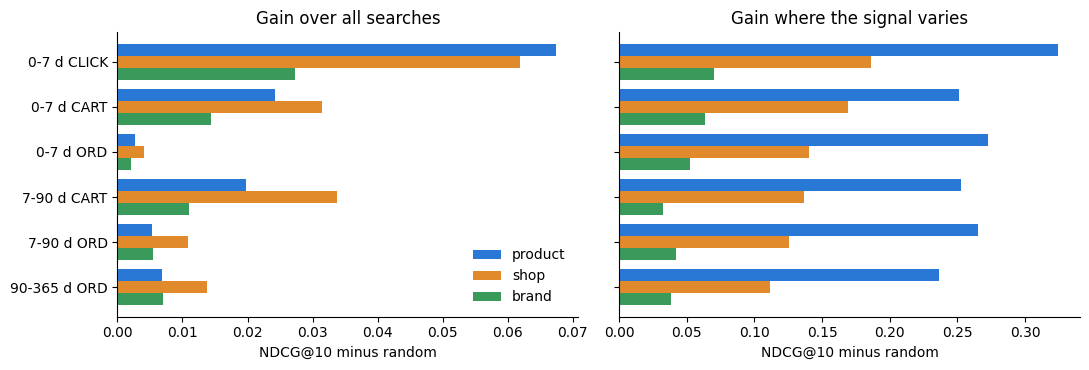

In [6]:
blocks = BLOCK_ORDER[3:]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, metric, title in [(axes[0], "gain_all", "Gain over all searches"),
                          (axes[1], "gain_where_varies", "Gain where the signal varies")]:
    data = e03[metric].unstack("level").reindex(blocks)[["product", "shop", "brand"]]
    data.plot.barh(ax=ax, color=["#2a78d6", "#e08a2c", "#3a9a5b"], width=0.8)
    ax.set(title=title, xlabel="NDCG@10 minus random", ylabel="")
    ax.invert_yaxis()
    ax.spines[["top", "right"]].set_visible(False)
axes[1].legend().remove()
axes[0].legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(OUT / "e03_gain_by_block.png", dpi=180, bbox_inches="tight")
plt.show()

**E03 reading** (19,733 searches with an engaged candidate):

- **Recent clicks carry most of the total signal.** 0-7 d clicks alone reach a product gain of 0.068 and a shop gain of 0.062, about 70% of the pooled history (0.093 and 0.088), because they cover the most searches (21% / 33%).
- **Type at fixed age (0-7 d):** per piece of evidence, clicks are at least as informative as carts and orders (product 0.32 vs 0.25 / 0.27; shop 0.19 vs 0.17 / 0.14). The "weaker" click signal in pooled data is a window artefact, not lower quality.
- **Age at fixed type:** the value of **broad** evidence fades with age: carts 0-7 d vs 7-90 d drop from 0.17 to 0.14 (shop) and 0.064 to 0.032 (brand); orders from 0-7 d to 90-365 d drop from 0.14 to 0.11 (shop) and 0.019 to 0.003 (L3 path). **Exact product** evidence barely fades (orders 0.27 / 0.27 / 0.24; carts 0.25 / 0.25).
- **Old history still helps:** carts and orders older than 7 days give a shop gain of 0.041 over all searches.

Consequence for features: one feature per (window, type, level) instead of pooled counts; broad matches (brand, category, shop) need age-aware weighting, exact product matches much less so.

## E04: does the context lead survive with action types held fixed?

The interim found larger history gains when the last action was recent. But shoppers inactive for 7+ days have **no clicks** by construction. We compare the gain by time since the last action for three signal sources:

- **pooled**: replicates the interim analysis;
- **no clicks**: removes the click window, so recently active shoppers lose their click advantage;
- **older than 7 d**: only carts and orders from 7+ days ago, which every shopper can have regardless of recent activity.

If the gradient persists for "older than 7 d", the search context itself changes how useful (even old) history is. If it disappears, the interim gradient came from the recent evidence itself.

In [7]:
seg_bins = [-1, 600, 6 * 3600, 7 * DAY, np.inf]
seg_names = ["< 10 min", "10 min - 6 h", "6 h - 7 d", "7+ d"]
search_info["since_last"] = pd.cut(search_info.last_gap_s, seg_bins, labels=seg_names)
e04_frame = signals[signals.block.isin(["pooled", "no clicks", "older than 7 d"])
                    & signals.level.isin(["product", "shop", "brand"])].join(search_info.since_last, on="session_id")

e04 = e04_frame.pivot_table(index=["block", "level"], columns="since_last", values="gain", aggfunc="mean",
                            observed=True).reindex(["pooled", "no clicks", "older than 7 d"], level=0)
print(search_info.since_last.value_counts().reindex(seg_names).to_string())
e04

since_last
< 10 min        7613
10 min - 6 h    2356
6 h - 7 d       7461
7+ d            2303


since_last              < 10 min  10 min - 6 h  6 h - 7 d   7+ d
block          level                                            
pooled         brand      0.0616        0.0267     0.0187 0.0087
               product    0.1692        0.0732     0.0434 0.0180
               shop       0.1379        0.0879     0.0577 0.0215
no clicks      brand      0.0338        0.0207     0.0171 0.0087
               product    0.0695        0.0439     0.0319 0.0180
               shop       0.0803        0.0685     0.0503 0.0215
older than 7 d brand      0.0149        0.0150     0.0158 0.0087
               product    0.0272        0.0286     0.0253 0.0180
               shop       0.0401        0.0530     0.0444 0.0215

In [8]:
def difference_interval(a, b, seed=4222, repeats=1000):
    # Mean(a) - mean(b) with a 95% bootstrap interval; independent resampling of the two groups.
    rng = np.random.default_rng(seed)
    a, b = np.asarray(a), np.asarray(b)
    diffs = [a[rng.integers(0, len(a), len(a))].mean() - b[rng.integers(0, len(b), len(b))].mean()
             for _ in range(repeats)]
    return a.mean() - b.mean(), *np.quantile(diffs, [0.025, 0.975])


rows = []
for (block, level), part in e04_frame.groupby(["block", "level"], sort=False):
    recent, later = part[part.since_last == "< 10 min"].gain, part[part.since_last == "6 h - 7 d"].gain
    rows.append((block, level, *difference_interval(recent, later)))
e04_diff = pd.DataFrame(rows, columns=["block", "level", "diff_<10min_minus_6h-7d", "ci_low", "ci_high"])
e04.to_csv(OUT / "e04_gain_by_recency.csv")
e04_diff.to_csv(OUT / "e04_recent_minus_later.csv", index=False)
e04_diff

,block,level,diff_<10min_minus_6h-7d,ci_low,ci_high
0,pooled,product,0.1258,0.1181,0.1346
1,pooled,brand,0.0429,0.0384,0.0476
2,pooled,shop,0.0803,0.0731,0.0873
3,no clicks,product,0.0376,0.0316,0.0438
4,no clicks,brand,0.0167,0.0128,0.0205
5,no clicks,shop,0.0301,0.0242,0.0355
6,older than 7 d,product,0.0019,-0.0027,0.0066
7,older than 7 d,brand,-0.0009,-0.0039,0.0023
8,older than 7 d,shop,-0.0042,-0.0089,0.0008


**E04 reading: the interim context lead is mostly a recency-of-evidence effect.**

- **Pooled** history replicates the interim gradient: same-product gain 0.169 when the last action was under 10 minutes ago vs 0.043 at 6 h - 7 d (difference 0.126 [0.118, 0.135]).
- **Without clicks** the gradient shrinks by about 70% (product 0.038 [0.032, 0.044], shop 0.030 [0.024, 0.036]); what remains comes from recent carts.
- **History older than 7 days** shows **no gradient**: product 0.002 [-0.003, 0.007], brand -0.001 [-0.004, 0.002], shop -0.004 [-0.009, 0.001]. Old evidence is equally useful whether or not the shopper was active minutes ago.

So history does not become more useful *because* the search continues a session; the search simply has fresh evidence (recent clicks and carts) available, and fresh evidence is the strongest. The ranking should weight evidence by **its own age and type**, not switch personalisation on and off by session state.

Open point: shoppers inactive for 7+ days get less from the same old history (shop 0.022 vs 0.040-0.053). Possible reasons: shorter histories or different shoppers; not yet checked.

## E05a: does history contain the current search's own interactions?

If the history included interactions from the current search, engaged candidates would often appear in history seconds before the search, under the same query. We compare engaged and ignored candidates: how often the product appears in history at all, and how recent the latest action on it is.

In [9]:
labels_all = np.concatenate([r["labels"] for r in records if (r["labels"] >= 1).any()])
n_engaged, n_ignored = int((labels_all >= 1).sum()), int((labels_all == 0).sum())
in_history["engaged"] = in_history.label >= 1
rows = []
for engaged, part in in_history.groupby("engaged"):
    total = n_engaged if engaged else n_ignored
    rows.append({
        "candidates": "engaged" if engaged else "ignored",
        "share_in_history": len(part) / total,
        "latest_within_1_min": (part.elapsed_s < 60).sum() / total,
        "latest_within_10_min": (part.elapsed_s < 600).sum() / total,
        "latest_within_1_h": (part.elapsed_s < 3600).sum() / total,
        "of_within_10_min_same_query": part[part.elapsed_s < 600].same_query.mean(),
    })
e05a = pd.DataFrame(rows).set_index("candidates")
e05a.to_csv(OUT / "e05a_recent_same_product.csv")
print(f"searches whose last action is under 1 min before the search: {(search_info.last_gap_s < 60).mean():.1%}")
e05a

searches whose last action is under 1 min before the search: 22.9%


,share_in_history,latest_within_1_min,latest_within_10_min,latest_within_1_h,of_within_10_min_same_query
candidates,,,,,
ignored,0.0059,0.0005,0.0018,0.0022,0.0069
engaged,0.0935,0.0214,0.0394,0.0462,0.0069


In [10]:
recent_engaged = in_history[in_history.engaged & (in_history.elapsed_s < 600)]
print("latest action type on engaged candidates seen in the last 10 minutes:")
recent_engaged.type.value_counts(normalize=True).to_frame("share")

latest action type on engaged candidates seen in the last 10 minutes:


,share
type,
CLICK,0.8299
CART,0.1618
ORD,0.0083


**E05a reading: no sign that history contains the current search's interactions.**

- Engaged candidates appear in history far more often than ignored ones (9.4% vs 0.6%), and more often very recently (latest action within 10 minutes: 3.9% vs 0.2%). Re-finding a product looked at minutes ago is real and strong.
- But only **0.7%** of those recent actions carry the current query (the same for engaged and ignored candidates). The current search's own clicks would carry the current query; these recent actions come from browsing or other searches (83% are clicks).
- 22.9% of searches follow the last action within a minute: shoppers often search right after browsing.

Consequence: keep recent history (it is legitimate), but report results with and without very recent same-product matches so the re-find share of the gain is visible. This is evidence against leakage, not proof: the dataset documentation is the only definitive source.

## E05b: do shop and brand matches help beyond re-finding the same product?

A shop match includes the candidate's own product whenever the shopper interacted with it before. Removing those actions leaves only evidence from **other** products of the same shop or brand: the part that generalises to products the shopper has never touched.

In [11]:
e05b = signal_table(signals[(signals.block == "pooled") & signals.level.isin(
    ["product", "shop", "shop excl. same product", "brand", "brand excl. same product"])])
e05b.to_csv(OUT / "e05b_excluding_same_product.csv")
e05b.droplevel("block")

,coverage,gain_all,gain_where_varies
level,,,
brand,0.5909,0.0350,0.0593
brand excl. same product,0.6121,0.0140,0.0229
product,0.2841,0.0925,0.3257
shop,0.5047,0.0880,0.1744
shop excl. same product,0.4980,0.0524,0.1051


**E05b reading: shop and brand evidence generalise beyond re-finds.**

- Shop matches on **other** products of the same shop keep 60% of the shop gain (0.052 of 0.088 over all searches; 0.105 vs 0.174 where it varies).
- Brand keeps 40% (0.014 of 0.035).

So shop and brand features help with the 80% of candidates that never appear in any history (cold items), not only by re-surfacing previously seen products. Exact-product and other-product matches should be separate features.

## Summary

| | Result | Consequence |
|---|---|---|
| **E03** | Recent clicks carry ~70% of the pooled signal; per piece of evidence clicks are at least as informative as carts/orders; broad evidence (brand, shop, category) fades with age, exact-product evidence hardly | Features per (window, type, level); age-aware weighting for broad matches |
| **E04** | The interim "history helps more right after the last action" vanishes for history older than 7 days (difference ~0) and shrinks ~70% without clicks | The context lead is a **recency-of-evidence** effect, not a session-context effect; weight evidence by its own age and type |
| **E05a** | Recent actions on engaged candidates almost never carry the current query (0.7%) | No sign of leakage; re-finds within minutes are real |
| **E05b** | 60% of the shop gain and 40% of the brand gain remain without the candidate's own product | Shop / brand features generalise to cold candidates; keep exact-product matches separate |

Results feed FINDINGS sections 6-7 and the feature design of `03_features`. Experiments E03-E05 in `docs/EXPERIMENT_LOG.md`.